# Gusman 2025 as a neuralset Study

`Gusman2025DragAndDrop` adapts the release into standardized events. **One timeline is one session**, five in total, following `kunz_2025`: the source concatenates a session's blocks onto a single continuous 20 ms grid with inter-block gaps removed, and the task tables index into that grid, so a session reads as one recording rather than a bag of clips.

Each timeline emits **three separate neural streams**, which is new for the catalog. Threshold crossings and spike-band power are the usual pair, and alongside them sit five local field potential bands. They have to be three types rather than one stacked array, because an extractor selects by type name and all three span the same time range.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np

from neuralshed.datasets.gusman_2025 import utils
from neuralshed.datasets.gusman_2025.study import Gusman2025DragAndDrop
from neuralshed.datasets.utils import dataset_dir
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

FS = utils.FS
PATH = str(dataset_dir("gusman_2025") / "data")

## Building the Study

The guard query takes two timelines, one per task, because the two tasks emit different rows. Only drag-and-drop carries the online decode and the `Intertrial` markers, and only Gesture Hero carries a cued hold duration.

In [2]:
study = Gusman2025DragAndDrop(path=PATH, query="timeline_index in [0, 2]")
events = study.run()

print(f"timelines in the full study: {study._info.num_timelines}")
print(f"events in this query: {len(events)} across {events.timeline.nunique()} timelines")
print(f"subjects: {sorted(events.subject.unique())}")
print()
print(events.groupby(["session", "type"]).size().to_string())

  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00,  1.79it/s]

100%|██████████| 2/2 [00:00<00:00,  3.21it/s]

100%|██████████| 2/2 [00:00<00:00,  2.87it/s]

timelines in the full study: 5
events in this query: 2692 across 2 timelines
subjects: ['Gusman2025DragAndDrop/T11']

session               type            
T11_drag_and_drop_s1  Action              1271
                      BandPower              1
                      BehavioralSeries       1
                      Intertrial           286
                      LfpBandPower           1
                      SpikeCounts            1
                      Stimulus             288
T11_gesture_hero_s1   Action               420
                      BandPower              1
                      LfpBandPower           1
                      SpikeCounts            1
                      Stimulus             420


## Three neural streams, three types

This is the part worth looking at. `SpikeCounts` and `BandPower` are the familiar pair, and `BandPower` holds all five short-time Fourier bands stacked on one channel axis, 5 bands times 192 electrodes.

It is a **sibling** of `BandPower` rather than a subclass. Subclassing would make an extractor asking for `"BandPower"` return the LFP stream too, and since both span the whole session they overlap, which the extractor rejects. The same reasoning produced `TargetGraspSeries` in `willsey_2025`.

In [3]:
streams = events[events.type.isin(["SpikeCounts", "BandPower", "BandPower", "BehavioralSeries"])]
print(streams[["session", "type", "feature", "duration", "frequency", "unit", "normalization"]].to_string(index=False))
print()
row = events[events.type == "BandPower"].iloc[0]
print(f"bands in row-block order: {row['bands']}")
print(f"processing: {row['processing']!r}")

             session             type               feature  duration  frequency       unit normalization
T11_drag_and_drop_s1      SpikeCounts   threshold_crossings   4393.54       50.0 counts/bin      z_scored
T11_drag_and_drop_s1        BandPower      spike_band_power   4393.54       50.0       uV^2      z_scored
T11_drag_and_drop_s1     LfpBandPower             lfp_bands   4393.54       50.0       uV^2      z_scored
T11_drag_and_drop_s1 BehavioralSeries online_gesture_decode   4393.54       50.0       a.u.           raw
 T11_gesture_hero_s1      SpikeCounts   threshold_crossings   3330.86       50.0 counts/bin      z_scored
 T11_gesture_hero_s1        BandPower      spike_band_power   3330.86       50.0       uV^2      z_scored
 T11_gesture_hero_s1     LfpBandPower             lfp_bands   3330.86       50.0       uV^2      z_scored

bands in row-block order: ('STFT 0-8', 'STFT 12-16', 'STFT 20-31', 'STFT 39-125', 'STFT 129-250')
processing: 'z-scored against a rolling 180 s window'

Reading them back gives three separately addressable arrays over the same time base. Note the row counts: 192, 192 and 960.

In [4]:
hero = events[events.task == "gesturehero"]

segmenter = ns.dataloader.Segmenter(
    extractors={
        "tx": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="SpikeCounts"),
        "sbp": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="BandPower"),
        "lfp": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="BandPower"),
    },
    trigger_query="type == 'Action' and action_kind == 'gesture_hold'",
    duration=None,
)
segments = segmenter.apply(hero)
segments.prepare()
segments.pad_duration = "auto"
batch = segments.load_all()

print({key: tuple(value.shape) for key, value in batch.data.items()})
print(f"\n{utils.N_CHANNELS} electrodes x 1 = tx, x 1 = sbp, x {len(utils.FEATURE_NAMES) - 2} bands = lfp")

2026-08-24 15:32:14 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-08-24 15:32:20 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-08-24 15:32:26 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


{'tx': (420, 192, 202), 'sbp': (420, 192, 202), 'lfp': (420, 960, 202)}

192 electrodes x 1 = tx, x 1 = sbp, x 5 bands = lfp


## Gesture Hero trials

One `Stimulus` and one `Action` per trial. The `Action` carries the cued hold, so the label a classifier wants and the condition it should be split on both arrive through `batch.triggers`.

In [5]:
triggers = batch.triggers.reset_index(drop=True)
print(f"trials: {len(triggers)}")
print(f"holds: {triggers.hold_s.value_counts().sort_index().to_dict()}")
print()
print(triggers.pivot_table(index="gesture", columns="hold_s", values="start", aggfunc="size", fill_value=0).to_string())

trials: 420
holds: {1.0: 140, 2.0: 140, 4.0: 140}

hold_s                     1.0  2.0  4.0
gesture                                 
Left thumb - down           20   20   20
Right hand - key grasp      20   20   20
Right hand - ok             20   20   20
Right hand - open           20   20   20
Right hand - power grasp    20   20   20
Right index finger - down   20   20   20
Right thumb - down          20   20   20


## Drag-and-drop stages

The other task emits one row per **stage**, so a trial spans several and `trial` groups them. Stages that are not part of an attempt become `Intertrial` rather than `Action`, and the stages that present a cue additionally emit a `Stimulus`.

In [6]:
drag = events[events.task == "draganddrop"]
actions = drag[drag.type == "Action"]
print(f"{len(actions)} Action rows over {actions.trial.nunique()} trials")
print(f"{(drag.type == 'Intertrial').sum()} Intertrial rows, {(drag.type == 'Stimulus').sum()} Stimulus rows")
print()
print("stages:")
print(actions.description.value_counts().to_string())

1271 Action rows over 288 trials
286 Intertrial rows, 288 Stimulus rows

stages:
description
Center Out                             288
Return                                 167
Prepare - Direction + Gesture click    126
Wait click                             126
Prepare - Direction + Gesture          121
Wait Gesture hold                      121
Return & Drag                          121
Hold                                   119
Prepare - Direction                     41
Wait Direction                          41


Closed-loop status rides the `Action` rows rather than the timeline, because the kinematic decoder and the gesture decoder close independently and it varies stage by stage. That is unusual: everywhere else in the catalog the loop type is a property of a block or a whole file.

In [7]:
print(f"stages with the kinematic decoder closed: {actions.kin_decoder_closed.sum():5d} of {len(actions)}")
print(f"stages with the gesture decoder closed:   {actions.gesture_decoder_closed.sum():5d}")
print(f"cursor error attenuation: {actions.kin_error_attenuation.value_counts().sort_index().to_dict()}")
print()
print("trial types:")
print(actions.attempt_type.value_counts().to_string())

stages with the kinematic decoder closed:  1147 of 1271
stages with the gesture decoder closed:     775
cursor error attenuation: {0.0: 1023, 0.30000001192092896: 124, 0.5: 124}

trial types:
attempt_type
Drag     603
Click    378
Move     290


## The online decoder as a stream

Drag-and-drop sessions carry the latch decoder's own per-bin decision, which the Study emits as a `BehavioralSeries` alongside the neural streams. Reading it against the cued gesture over the same windows shows how often the decoder agreed with the cue, without re-implementing anything.

In [8]:
drag_segmenter = ns.dataloader.Segmenter(
    extractors={
        "decoded": BehavioralSeriesExtractor(frequency=FS, event_types="BehavioralSeries"),
    },
    trigger_query="type == 'Action' and is_drag",
    duration=None,
)
drag_segments = drag_segmenter.apply(drag)
drag_segments.prepare()
drag_segments.pad_duration = "auto"
drag_batch = drag_segments.load_all()

decoded = drag_batch.data["decoded"].numpy()[:, 0, :]
cued = drag_batch.triggers.gesture.to_numpy()
print(f"drag stages: {decoded.shape[0]}, padded to {decoded.shape[1]} bins")

# The stream holds a class index over the session's states, sorted alphabetically.
states = sorted(set(utils.decoded_state(utils.list_sessions(PATH)[0])))
print(f"states: {states}")

2026-08-24 15:32:57 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


drag stages: 361, padded to 1251 bins


states: ['Right hand - ok', 'Right hand - power grasp', 'Right index finger - down', 'no_action']


median fraction held: 66.6%
stages held for more than half the time: 52.4%


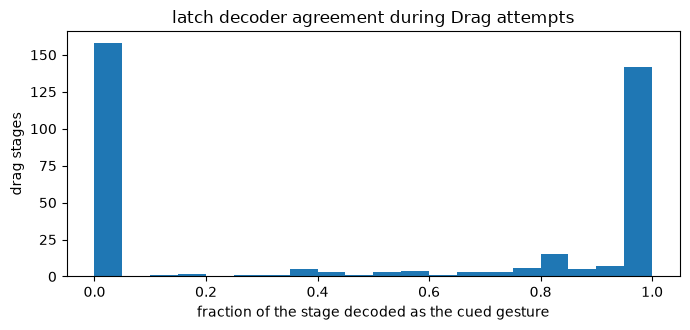

In [9]:
# Fraction of each stage's bins where the decoder held the cued gesture.
held = []
for row in range(decoded.shape[0]):
    n = int(round(float(drag_batch.triggers.duration.iloc[row]) * FS))
    codes = decoded[row, :n].astype(int)
    target = states.index(cued[row]) if cued[row] in states else -1
    held.append((codes == target).mean() if n else np.nan)
held = np.array(held)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(held[~np.isnan(held)], bins=np.linspace(0, 1, 21), color="C0")
ax.set(xlabel="fraction of the stage decoded as the cued gesture", ylabel="drag stages",
       title="latch decoder agreement during Drag attempts")
plt.tight_layout()

print(f"median fraction held: {np.nanmedian(held):.1%}")
print(f"stages held for more than half the time: {(held > 0.5).mean():.1%}")

## Summary

- Five timelines, one per session, since the source concatenates blocks onto a continuous grid the way `kunz_2025` does.
- Three neural streams per timeline as three distinct types: `SpikeCounts` at 192 rows, `BandPower` at 192, and `BandPower` at 960 for the five bands. All three are z-scored against a rolling 3 minute window, so none converts through a bin rate.
- `BandPower` is a sibling of `BandPower`, not a subclass, for the same reason `TargetGraspSeries` is a sibling of `GraspSeries`: same-typed streams that overlap in time collide.
- Gesture Hero emits one `Stimulus` and one `Action` per trial with the cued hold on the row. Drag-and-drop emits one row per stage, with `Intertrial` for the gaps.
- Closed-loop status is per stage and per decoder, so it rides the `Action` rows rather than the timeline. Nothing else in the catalog needs that.
- The latch decoder's own output is in the release at full rate and is emitted as a stream, so its behaviour can be read directly rather than reproduced.